### decision tree estimator for random forest complusory


# Glass Identification

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor

from IPython.display import Image

In [3]:
glass=pd.read_csv("D:\Machine Learning\Datasets\Cases\Glass_Identification\Glass.csv")

In [4]:
from sklearn.preprocessing import OneHotEncoder

from sklearn.compose import make_column_selector
from tqdm import tqdm
X, y = glass.drop("Type", axis=1), glass["Type"]
ohe = OneHotEncoder(drop='first', sparse_output=False).set_output(transform="pandas")
col_transformer = ColumnTransformer([("OHE", ohe, make_column_selector(dtype_include=object))], 
                                    remainder='passthrough', 
                                    verbose_feature_names_out=False)
col_transformer = col_transformer.set_output(transform="pandas")
X = col_transformer.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=25)


HyperParameter Tuning

In [ ]:



features=[2,3,4,5]
n_est=[25,50,100,150,200]
scores=[]
for f in features:
    for n in n_est:
        rf=RandomForestClassifier(random_state=25,max_features=f,n_estimators=n)
        rf.fit(X_train,y_train)
        y_pred=rf.predict(X_test)
        scores.append([f,n,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=('Feature',"Tree",'Score'))
df_scores.sort_values('Score',ascending=False)

,Feature,Tree,Score
3,2,150,0.860465
1,2,50,0.837209
2,2,100,0.837209
0,2,25,0.813953
4,2,200,0.813953
12,4,100,0.813953
7,3,100,0.790698
6,3,50,0.790698
11,4,50,0.790698
9,3,200,0.790698


## Feature Importance

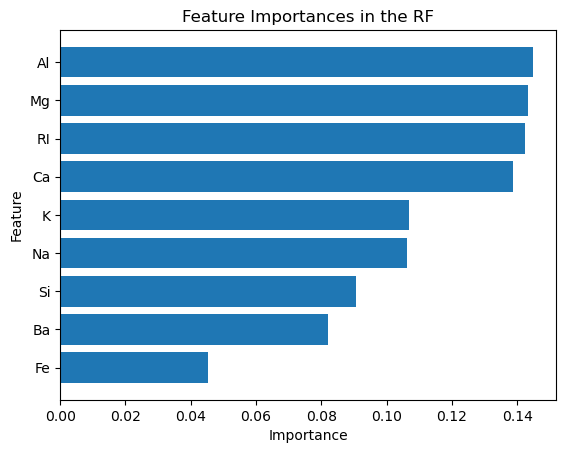

In [8]:
best_tree=RandomForestClassifier(random_state=25,max_features=2,n_estimators=150)
best_tree.fit(X, y)
df_imp = pd.DataFrame({"feature": X.columns, "importance": best_tree.feature_importances_})
df_imp = df_imp.sort_values("importance")
import matplotlib.pyplot as plt
plt.barh(df_imp["feature"], df_imp["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importances in the RF")
plt.show()

# Concrete Strength

In [10]:
concrete=pd.read_csv("D:\Machine Learning\Datasets\Cases\Concrete_Strength\Concrete_Data.csv")
concrete

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [16]:
X=concrete.drop('Strength',axis=1)
y=concrete['Strength']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [17]:
from sklearn.metrics import mean_absolute_error


features=[2,3,4,5]
n_est=[25,50,100,150,200]
scores=[]
for f in features:
    for n in n_est:
        rf=RandomForestRegressor(random_state=42,max_features=f,n_estimators=n)
        rf.fit(X_train,y_train)
        y_pred=rf.predict(X_test)
        scores.append([f,n,mean_absolute_error(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=('Feature',"Tree",'Score'))
df_scores.sort_values('Score')

,Feature,Tree,Score
19,5,200,3.682840
18,5,150,3.701540
13,4,150,3.738819
14,4,200,3.741961
17,5,100,3.742299
11,4,50,3.748734
12,4,100,3.764157
16,5,50,3.807694
9,3,200,3.810154
10,4,25,3.817647


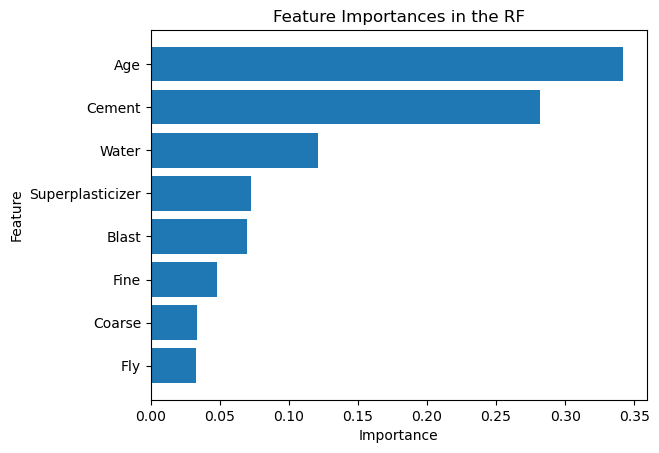

In [18]:
best_tree=RandomForestRegressor(random_state=42,max_features=5,n_estimators=200)
best_tree.fit(X, y)
df_imp = pd.DataFrame({"feature": X.columns, "importance": best_tree.feature_importances_})
df_imp = df_imp.sort_values("importance")
import matplotlib.pyplot as plt
plt.barh(df_imp["feature"], df_imp["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importances in the RF")
plt.show()